i) Importing Required Libraries

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully!")


Libraries imported successfully!


Step 2: Load your supply chain dataset

In [3]:

# Load the dataset
df = pd.read_csv(
    r"C:\Users\gk442\Downloads\sp.csv",
    encoding="latin1",
    low_memory=False
)

# Preview the dataset
display(df.head())

print("Dataset loaded successfully!")


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Date,Order Time,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Shipping time,Shipping Date,Calculated shipping date,Order Year.,Order Month Number,Order Month Name,Order Quarter,Order Day,WeekDay Name,Weekend / Weekday,Shipping Year,Shipping Month,Shipping Quarter,Shipping Day Name,weekend/day,Sales Categories,Profit Category,Discount Category,Order Hour,Time Slot,Profit Margin %,Shipping Duration (days)
0,DEBIT,3,4,$91.25,$314.64,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Bekasi,Indonesia,20755,31-01-2018,22:56:00,1/31/2018 22:56,77202,1360,13.11,4%,180517,$327.75,29%,1,327.75,$314.64,91.25,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,02-03-2018,Standard Class,22:56:00,02-03-2018,03-02-2018,2018,1,January,Q1,31,Wednesday,Weekday,2018,February,Q1,Saturday,Weekend,High,Profit,Low Discount,10:56 PM,Night,27.84%,3
1,TRANSFER,5,4,$-249.09,$311.36,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.00,2,Fitness,18.28,-66.04,Pacific Asia,Bikaner,India,19492,13-01-2018,12:27:00,1/13/2018 12:27,75939,1360,16.39,5%,179254,$327.75,-80%,1,327.75,$311.36,-249.09,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,1/18/2018 12:27,Standard Class,12:27:00,18-01-2018,18-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Thursday,Weekday,High,Loss,Low Discount,12:27 PM,Night,-76.00%,5
2,CASH,4,4,$-247.78,$309.72,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,"95,125.00",2,Fitness,37.29,-121.88,Pacific Asia,Bikaner,India,19491,13-01-2018,12:06:00,1/13/2018 12:06,75938,1360,18.03,6%,179253,$327.75,-80%,1,327.75,$309.72,-247.78,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,1/17/2018 12:06,Standard Class,12:06:00,17-01-2018,17-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Wednesday,Weekday,High,Loss,Low Discount,12:06 PM,Night,-75.60%,4
3,DEBIT,3,4,$22.86,$304.81,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,"90,027.00",2,Fitness,34.13,-118.29,Pacific Asia,Townsville,Australia,19490,13-01-2018,11:45:00,1/13/2018 11:45,75937,1360,22.94,7%,179252,$327.75,8%,1,327.75,$304.81,22.86,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,1/16/2018 11:45,Standard Class,11:45:00,16-01-2018,16-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Tuesday,Weekday,High,Profit,Low Discount,11:45 AM,Night,6.97%,3
4,PAYMENT,2,4,$134.21,$298.25,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Townsville,Australia,19489,13-01-2018,11:24:00,1/13/2018 11:24,75936,1360,29.50,9%,179251,$327.75,45%,1,327.75,$298.25,134.21,Oceania,Queensland,PENDING_PAYMENT,

Dataset loaded successfully!


Step 3: Inspect the data

In [4]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values by column:")
display(
    df.isnull().sum()
       .sort_values(ascending=False)
       .head(15)
)

print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (180519, 75)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'Order Date', 'Order Time', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Card Id', 'Product Category Id', 'Product Image', 'Product Name', 'Product Price', 'Product St

Customer Lname                   8
Customer Zipcode                 3
Type                             0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Customer Country                 0
Customer City                    0
Customer Fname                   0
Customer Email                   0
dtype: int64


Duplicate rows: 0


Step 4: Check dates, numeric columns, and data quality

In [5]:

# 1. Check important columns
important_columns = [
    "order date (DateOrders)",
    "shipping date (DateOrders)",
    "Sales",
    "Order Profit Per Order",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Late_delivery_risk",
    "Shipping Mode",
    "Market",
    "Category Name"
]

for col in important_columns:
    if col in df.columns:
        print(f"{col}: available")
    else:
        print(f"{col}: not found — check the column name")

# 2. Check missing values in important columns
available_columns = [
    col for col in important_columns if col in df.columns
]

display(df[available_columns].isnull().sum().to_frame("Missing Values"))

# 3. Check data types
display(df[available_columns].dtypes.to_frame("Data Type"))

# 4. Check numeric summaries
numeric_columns = [
    col for col in [
        "Sales",
        "Order Profit Per Order",
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "Late_delivery_risk"
    ]
    if col in df.columns
]

display(df[numeric_columns].describe().T)


order date (DateOrders): available
shipping date (DateOrders): available
Sales: available
Order Profit Per Order: available
Days for shipping (real): available
Days for shipment (scheduled): available
Late_delivery_risk: available
Shipping Mode: available
Market: available
Category Name: available


,Missing Values
order date (DateOrders),0
shipping date (DateOrders),0
Sales,0
Order Profit Per Order,0
Days for shipping (real),0
Days for shipment (scheduled),0
Late_delivery_risk,0
Shipping Mode,0
Market,0
Category Name,0


,Data Type
order date (DateOrders),str
shipping date (DateOrders),str
Sales,float64
Order Profit Per Order,float64
Days for shipping (real),int64
Days for shipment (scheduled),int64
Late_delivery_risk,int64
Shipping Mode,str
Market,str
Category Name,str


,count,mean,std,min,25%,50%,75%,max
Sales,"180,519.00",203.77,132.27,9.99,119.98,199.92,299.95,"1,999.99"
Order Profit Per Order,"180,519.00",21.97,104.43,"-4,274.98",7.00,31.52,64.80,911.80
Days for shipping (real),"180,519.00",3.50,1.62,0.00,2.00,3.00,5.00,6.00
Days for shipment (scheduled),"180,519.00",2.93,1.37,0.00,2.00,4.00,4.00,4.00
Late_delivery_risk,"180,519.00",0.55,0.50,0.00,0.00,1.00,1.00,1.00


Step 5: Clean and validate the data

In [6]:

# Create a working copy
df_clean = df.copy()

# 1. Standardize column names by removing extra spaces
df_clean.columns = df_clean.columns.str.strip()

# 2. Convert date columns to datetime
date_columns = [
    "order date (DateOrders)",
    "shipping date (DateOrders)"
]

for col in date_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_datetime(
            df_clean[col], errors="coerce"
        )

# 3. Convert important numeric columns safely
numeric_columns = [
    "Sales",
    "Order Profit Per Order",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Late_delivery_risk"
]

for col in numeric_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# 4. Create a delay-days column
if (
    "Days for shipping (real)" in df_clean.columns
    and "Days for shipment (scheduled)" in df_clean.columns
):
    df_clean["Delay_Days_Calculated"] = (
        df_clean["Days for shipping (real)"]
        - df_clean["Days for shipment (scheduled)"]
    )

# 5. Review the prepared data
print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

print("\nUpdated data types:")
display(df_clean.dtypes.to_frame("Data Type"))

print("\nSample cleaned records:")
display(df_clean.head())


Original shape: (180519, 75)
Working copy shape: (180519, 76)

Updated data types:


,Data Type
Type,str
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,str
Sales per customer,str
...,...
Order Hour,str
Time Slot,str
Profit Margin %,str
Shipping Duration (days),int64



Sample cleaned records:


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Date,Order Time,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Shipping time,Shipping Date,Calculated shipping date,Order Year.,Order Month Number,Order Month Name,Order Quarter,Order Day,WeekDay Name,Weekend / Weekday,Shipping Year,Shipping Month,Shipping Quarter,Shipping Day Name,weekend/day,Sales Categories,Profit Category,Discount Category,Order Hour,Time Slot,Profit Margin %,Shipping Duration (days),Delay_Days_Calculated
0,DEBIT,3,4,$91.25,$314.64,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Bekasi,Indonesia,20755,31-01-2018,22:56:00,2018-01-31 22:56:00,77202,1360,13.11,4%,180517,$327.75,29%,1,327.75,$314.64,91.25,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,2018-02-03,Standard Class,22:56:00,02-03-2018,03-02-2018,2018,1,January,Q1,31,Wednesday,Weekday,2018,February,Q1,Saturday,Weekend,High,Profit,Low Discount,10:56 PM,Night,27.84%,3,-1
1,TRANSFER,5,4,$-249.09,$311.36,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.00,2,Fitness,18.28,-66.04,Pacific Asia,Bikaner,India,19492,13-01-2018,12:27:00,2018-01-13 12:27:00,75939,1360,16.39,5%,179254,$327.75,-80%,1,327.75,$311.36,-249.09,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,NaT,Standard Class,12:27:00,18-01-2018,18-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Thursday,Weekday,High,Loss,Low Discount,12:27 PM,Night,-76.00%,5,1
2,CASH,4,4,$-247.78,$309.72,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,"95,125.00",2,Fitness,37.29,-121.88,Pacific Asia,Bikaner,India,19491,13-01-2018,12:06:00,2018-01-13 12:06:00,75938,1360,18.03,6%,179253,$327.75,-80%,1,327.75,$309.72,-247.78,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,NaT,Standard Class,12:06:00,17-01-2018,17-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Wednesday,Weekday,High,Loss,Low Discount,12:06 PM,Night,-75.60%,4,0
3,DEBIT,3,4,$22.86,$304.81,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,"90,027.00",2,Fitness,34.13,-118.29,Pacific Asia,Townsville,Australia,19490,13-01-2018,11:45:00,2018-01-13 11:45:00,75937,1360,22.94,7%,179252,$327.75,8%,1,327.75,$304.81,22.86,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,NaT,Standard Class,11:45:00,16-01-2018,16-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Tuesday,Weekday,High,Profit,Low Discount,11:45 AM,Night,6.97%,3,-1
4,PAYMENT,2,4,$134.21,$298.25,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Townsville,Australia,19489,13-01-2018,11:24:00,2018-01-13 11:24:00,75936,1360,29.50,9%,179251,$327.75,45%,1,327.75,$298.25,134.21,Oceania,Queensland,

In [7]:

# Check shipping date columns in the imported dataset
print("Available date-related columns:")

for col in df_clean.columns:
    if "shipping" in col.lower() or "date" in col.lower():
        print(col)

# Preview order date and actual shipping date
display(df_clean.head(5))


Available date-related columns:
Days for shipping (real)
Order Date
order date (DateOrders)
shipping date (DateOrders)
Shipping Mode
Shipping time
Shipping Date
Calculated shipping date
Shipping Year
Shipping Month
Shipping Quarter
Shipping Day Name
Shipping Duration (days)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Date,Order Time,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Shipping time,Shipping Date,Calculated shipping date,Order Year.,Order Month Number,Order Month Name,Order Quarter,Order Day,WeekDay Name,Weekend / Weekday,Shipping Year,Shipping Month,Shipping Quarter,Shipping Day Name,weekend/day,Sales Categories,Profit Category,Discount Category,Order Hour,Time Slot,Profit Margin %,Shipping Duration (days),Delay_Days_Calculated
0,DEBIT,3,4,$91.25,$314.64,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Bekasi,Indonesia,20755,31-01-2018,22:56:00,2018-01-31 22:56:00,77202,1360,13.11,4%,180517,$327.75,29%,1,327.75,$314.64,91.25,Southeast Asia,Java Occidental,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,2018-02-03,Standard Class,22:56:00,02-03-2018,03-02-2018,2018,1,January,Q1,31,Wednesday,Weekday,2018,February,Q1,Saturday,Weekend,High,Profit,Low Discount,10:56 PM,Night,27.84%,3,-1
1,TRANSFER,5,4,$-249.09,$311.36,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.00,2,Fitness,18.28,-66.04,Pacific Asia,Bikaner,India,19492,13-01-2018,12:27:00,2018-01-13 12:27:00,75939,1360,16.39,5%,179254,$327.75,-80%,1,327.75,$311.36,-249.09,South Asia,Rajastán,PENDING,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,NaT,Standard Class,12:27:00,18-01-2018,18-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Thursday,Weekday,High,Loss,Low Discount,12:27 PM,Night,-76.00%,5,1
2,CASH,4,4,$-247.78,$309.72,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,"95,125.00",2,Fitness,37.29,-121.88,Pacific Asia,Bikaner,India,19491,13-01-2018,12:06:00,2018-01-13 12:06:00,75938,1360,18.03,6%,179253,$327.75,-80%,1,327.75,$309.72,-247.78,South Asia,Rajastán,CLOSED,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,NaT,Standard Class,12:06:00,17-01-2018,17-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Wednesday,Weekday,High,Loss,Low Discount,12:06 PM,Night,-75.60%,4,0
3,DEBIT,3,4,$22.86,$304.81,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,"90,027.00",2,Fitness,34.13,-118.29,Pacific Asia,Townsville,Australia,19490,13-01-2018,11:45:00,2018-01-13 11:45:00,75937,1360,22.94,7%,179252,$327.75,8%,1,327.75,$304.81,22.86,Oceania,Queensland,COMPLETE,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,$327.75,0,NaT,Standard Class,11:45:00,16-01-2018,16-01-2018,2018,1,January,Q1,13,Saturday,Weekend,2018,January,Q1,Tuesday,Weekday,High,Profit,Low Discount,11:45 AM,Night,6.97%,3,-1
4,PAYMENT,2,4,$134.21,$298.25,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.00,2,Fitness,18.25,-66.04,Pacific Asia,Townsville,Australia,19489,13-01-2018,11:24:00,2018-01-13 11:24:00,75936,1360,29.50,9%,179251,$327.75,45%,1,327.75,$298.25,134.21,Oceania,Queensland,

Step 6 — Exploratory Data Analysis (EDA)
Step 6A — Overall business performance

In [8]:

# Overall business KPIs
total_records = len(df_clean)
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Order Profit Per Order"].sum()
average_sales_per_record = df_clean["Sales"].mean()

print("SUPPLY CHAIN BUSINESS SUMMARY")
print("-" * 40)
print(f"Total records: {total_records:,}")
print(f"Total sales: ${total_sales:,.2f}")
print(f"Total profit: ${total_profit:,.2f}")
print(f"Average sales per record: ${average_sales_per_record:,.2f}")

# Profit margin
profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)
print(f"Profit margin: {profit_margin:.2f}%")

SUPPLY CHAIN BUSINESS SUMMARY
----------------------------------------
Total records: 180,519
Total sales: $36,784,734.31
Total profit: $3,966,902.97
Average sales per record: $203.77
Profit margin: 10.78%


Step 6B — Sales and profit by market

In [9]:

# Aggregate sales and profit by market
market_analysis = (
    df_clean.groupby("Market", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Record_Count=("Market", "size")
    )
    .reset_index()
)

market_analysis["Profit_Margin_Percent"] = (
    market_analysis["Total_Profit"]
    .div(market_analysis["Total_Sales"].replace(0, np.nan))
    .mul(100)
)

market_analysis = market_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(market_analysis.round(2))


,Market,Total_Sales,Total_Profit,Record_Count,Profit_Margin_Percent
1,Europe,"10,872,396.60","1,169,442.96",50252,10.76
2,LATAM,"10,277,612.64","1,123,321.61",51594,10.93
3,Pacific Asia,"8,273,743.58","857,753.44",41260,10.37
4,USCA,"5,066,528.61","564,313.78",25799,11.14
0,Africa,"2,294,452.88","252,071.18",11614,10.99


Step 6C — Visualize market sales

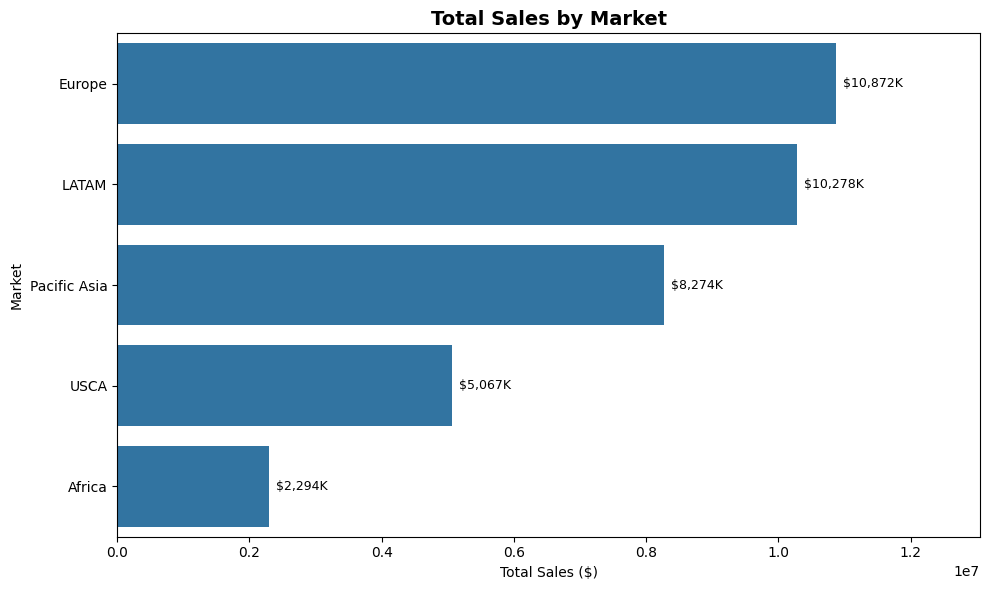

In [10]:

# Visualize market sales with K-format data labels
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=market_analysis,
    x="Total_Sales",
    y="Market"
)

# Format labels in K
labels = [
    f"${value / 1000:,.0f}K"
    for value in market_analysis["Total_Sales"]
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=5,
    fontsize=9
)

plt.title("Total Sales by Market", fontsize=14, fontweight="bold")
plt.xlabel("Total Sales ($)")
plt.ylabel("Market")

# Extra space for labels
plt.xlim(0, market_analysis["Total_Sales"].max() * 1.20)

plt.tight_layout()
plt.show()




Step 7 — Category Profitability Analysis

In [11]:

# Aggregate sales and profit by product category
category_analysis = (
    df_clean.groupby("Category Name", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Record_Count=("Category Name", "size")
    )
    .reset_index()
)

# Calculate profit margin
category_analysis["Profit_Margin_Percent"] = (
    category_analysis["Total_Profit"]
    .div(category_analysis["Total_Sales"].replace(0, np.nan))
    .mul(100)
)

# Sort by sales
category_analysis = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

display(category_analysis.round(2))

,Category Name,Total_Sales,Total_Profit,Record_Count,Profit_Margin_Percent
18,Fishing,"6,929,653.50","756,220.76",17325,10.91
12,Cleats,"4,431,942.66","494,636.92",24551,11.16
9,Camping & Hiking,"4,118,425.42","427,455.57",13729,10.38
10,Cardio Equipment,"3,694,843.20","383,011.10",12487,10.37
47,Women's Apparel,"3,147,800.00","350,421.03",21035,11.13
46,Water Sports,"3,113,844.60","325,146.96",15540,10.44
34,Men's Footwear,"2,891,757.54","311,902.82",22246,10.79
30,Indoor/Outdoor Games,"2,888,993.94","318,451.43",19298,11.02
38,Shop By Sport,"1,309,522.02","129,813.96",10984,9.91
13,Computers,"663,000.00","69,656.81",442,10.51


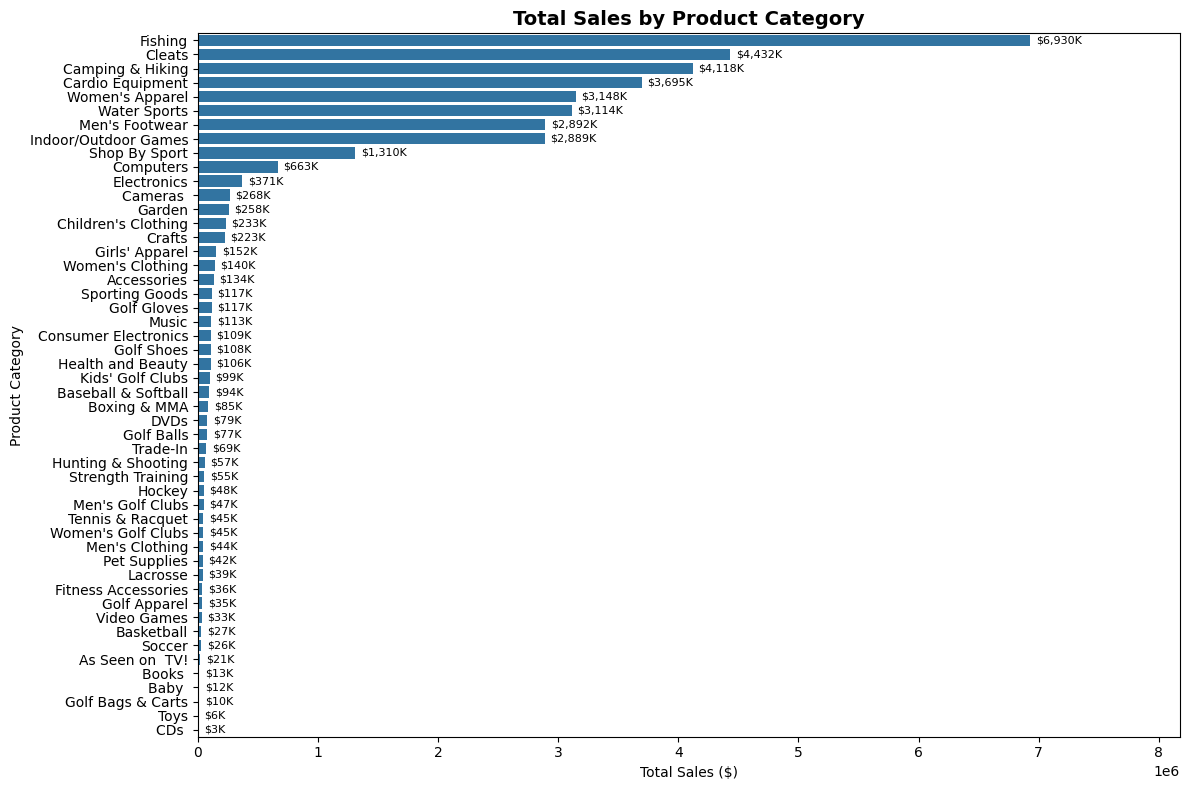

In [12]:
#Step 7B — Visualize sales by category

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=category_analysis,
    x="Total_Sales",
    y="Category Name"
)

labels = [
    f"${value / 1000:,.0f}K"
    for value in category_analysis["Total_Sales"]
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=4,
    fontsize=8
)

plt.title(
    "Total Sales by Product Category",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Category")

plt.xlim(0, category_analysis["Total_Sales"].max() * 1.18)
plt.tight_layout()
plt.show()


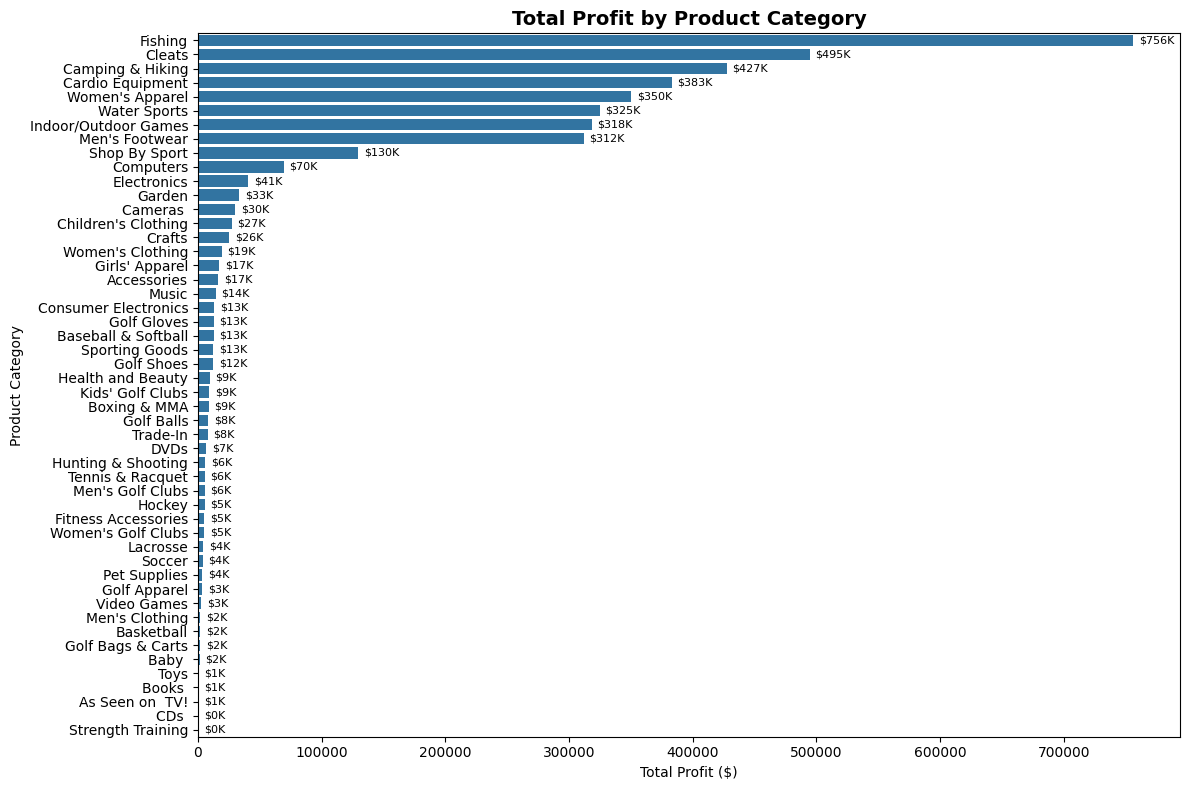

In [13]:
#Step 8 — Profit by Category

# Sort categories by total profit
profit_by_category = category_analysis.sort_values(
    "Total_Profit", ascending=False
)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=profit_by_category,
    x="Total_Profit",
    y="Category Name"
)

# Add K-format labels, including negative profits
labels = [
    f"${value / 1000:,.0f}K"
    for value in profit_by_category["Total_Profit"]
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=4,
    fontsize=8
)

plt.title(
    "Total Profit by Product Category",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()


In [14]:
#Step 8B — Find the strongest and weakest categories

print("TOP 5 MOST PROFITABLE CATEGORIES")
display(
    profit_by_category[
        ["Category Name", "Total_Sales", "Total_Profit",
         "Profit_Margin_Percent"]
    ].head(5).round(2)
)

print("\nBOTTOM 5 CATEGORIES BY PROFIT")
display(
    profit_by_category[
        ["Category Name", "Total_Sales", "Total_Profit",
         "Profit_Margin_Percent"]
    ].tail(5).sort_values("Total_Profit").round(2)
)


TOP 5 MOST PROFITABLE CATEGORIES


,Category Name,Total_Sales,Total_Profit,Profit_Margin_Percent
18,Fishing,"6,929,653.50","756,220.76",10.91
12,Cleats,"4,431,942.66","494,636.92",11.16
9,Camping & Hiking,"4,118,425.42","427,455.57",10.38
10,Cardio Equipment,"3,694,843.20","383,011.10",10.37
47,Women's Apparel,"3,147,800.00","350,421.03",11.13



BOTTOM 5 CATEGORIES BY PROFIT


,Category Name,Total_Sales,Total_Profit,Profit_Margin_Percent
41,Strength Training,"54,895.53",332.31,0.61
7,CDs,"3,059.59",383.85,12.55
1,As Seen on TV!,"20,597.94",714.43,3.47
5,Books,"12,587.40",883.01,7.02
43,Toys,"6,104.66",900.71,14.75


step 9 - Shipping & Delivery Performance Analysis

In [15]:

# Inspect the original values before converting them
print("Calculated shipping date — sample values:")
display(df["Calculated shipping date"].head(10))

print("\nData type:")
print(df["Calculated shipping date"].dtype)

print("\nMissing values:")
print(df["Calculated shipping date"].isna().sum())

print("\nOrder date — sample values:")
display(df["order date (DateOrders)"].head(10))


Calculated shipping date — sample values:


0    03-02-2018
1    18-01-2018
2    17-01-2018
3    16-01-2018
4    15-01-2018
5    19-01-2018
6    15-01-2018
7    15-01-2018
8    16-01-2018
9    15-01-2018
Name: Calculated shipping date, dtype: str


Data type:
str

Missing values:
0

Order date — sample values:


0    1/31/2018 22:56
1    1/13/2018 12:27
2    1/13/2018 12:06
3    1/13/2018 11:45
4    1/13/2018 11:24
5    1/13/2018 11:03
6    1/13/2018 10:42
7    1/13/2018 10:21
8    1/13/2018 10:00
9     1/13/2018 9:39
Name: order date (DateOrders), dtype: str

In [16]:

# Rebuild the date column from the original string data
df_clean["Calculated shipping date"] = pd.to_datetime(
    df["Calculated shipping date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)

print("Successfully converted:",
      df_clean["Calculated shipping date"].notna().sum())

print("Missing dates:",
      df_clean["Calculated shipping date"].isna().sum())

display(df_clean[["Calculated shipping date"]].head(10))


Successfully converted: 180519
Missing dates: 0


,Calculated shipping date
0,2018-02-03
1,2018-01-18
2,2018-01-17
3,2018-01-16
4,2018-01-15
5,2018-01-19
6,2018-01-15
7,2018-01-15
8,2018-01-16
9,2018-01-15


In [17]:

# Calculate elapsed calendar days
df_clean["Calculated Shipping Days"] = (
    df_clean["Calculated shipping date"].dt.normalize()
    - df_clean["order date (DateOrders)"].dt.normalize()
).dt.days

display(
    df_clean[
        [
            "order date (DateOrders)",
            "Calculated shipping date",
            "Days for shipping (real)",
            "Calculated Shipping Days"
        ]
    ].head(10)
)


,order date (DateOrders),Calculated shipping date,Days for shipping (real),Calculated Shipping Days
0,2018-01-31 22:56:00,2018-02-03,3,3.00
1,2018-01-13 12:27:00,2018-01-18,5,5.00
2,2018-01-13 12:06:00,2018-01-17,4,4.00
3,2018-01-13 11:45:00,2018-01-16,3,3.00
4,2018-01-13 11:24:00,2018-01-15,2,2.00
5,2018-01-13 11:03:00,2018-01-19,6,6.00
6,2018-01-13 10:42:00,2018-01-15,2,2.00
7,2018-01-13 10:21:00,2018-01-15,2,2.00
8,2018-01-13 10:00:00,2018-01-16,3,3.00
9,2018-01-13 09:39:00,2018-01-15,2,2.00


In [18]:

# Compare existing and date-calculated shipping duration
df_clean["Shipping Days Difference"] = (
    df_clean["Calculated Shipping Days"]
    - df_clean["Days for shipping (real)"]
)

print("Rows compared:",
      df_clean["Shipping Days Difference"].notna().sum())

print("Rows where durations match:",
      (df_clean["Shipping Days Difference"] == 0).sum())

print("Rows where durations differ:",
      (df_clean["Shipping Days Difference"] != 0).sum())

print("\nSample comparison:")
display(
    df_clean[
        [
            "order date (DateOrders)",
            "Calculated shipping date",
            "Days for shipping (real)",
            "Calculated Shipping Days",
            "Shipping Days Difference"
        ]
    ].head(10)
)

Rows compared: 109416
Rows where durations match: 109416
Rows where durations differ: 71103

Sample comparison:


,order date (DateOrders),Calculated shipping date,Days for shipping (real),Calculated Shipping Days,Shipping Days Difference
0,2018-01-31 22:56:00,2018-02-03,3,3.00,0.00
1,2018-01-13 12:27:00,2018-01-18,5,5.00,0.00
2,2018-01-13 12:06:00,2018-01-17,4,4.00,0.00
3,2018-01-13 11:45:00,2018-01-16,3,3.00,0.00
4,2018-01-13 11:24:00,2018-01-15,2,2.00,0.00
5,2018-01-13 11:03:00,2018-01-19,6,6.00,0.00
6,2018-01-13 10:42:00,2018-01-15,2,2.00,0.00
7,2018-01-13 10:21:00,2018-01-15,2,2.00,0.00
8,2018-01-13 10:00:00,2018-01-16,3,3.00,0.00
9,2018-01-13 09:39:00,2018-01-15,2,2.00,0.00


In [19]:
# Validate shipping durations across all records
valid_rows = df_clean[
    ["Calculated Shipping Days", "Days for shipping (real)"]
].dropna()

matching_rows = (
    valid_rows["Calculated Shipping Days"]
    == valid_rows["Days for shipping (real)"]
).sum()

differing_rows = len(valid_rows) - matching_rows

print(f"Valid rows compared: {len(valid_rows):,}")
print(f"Matching rows: {matching_rows:,}")
print(f"Differing rows: {differing_rows:,}")
print(f"Match percentage: {matching_rows / len(valid_rows) * 100:.2f}%")


Valid rows compared: 109,416
Matching rows: 109,416
Differing rows: 0
Match percentage: 100.00%


Step 11 — Shipping performance by mode

In [20]:

# Analyze shipping performance by mode
shipping_analysis = (
    df_clean.groupby("Shipping Mode", dropna=False)
    .agg(
        Total_Records=("Shipping Mode", "size"),
        Average_Actual_Shipping_Days=("Calculated Shipping Days", "mean"),
        Average_Scheduled_Shipping_Days=("Days for shipment (scheduled)", "mean"),
        Average_Delay_Days=("Shipping Days Difference", "mean")
    )
    .reset_index()
    .round(2)
)

display(shipping_analysis)


,Shipping Mode,Total_Records,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Average_Delay_Days
0,First Class,27814,2.00,1.00,0.00
1,Same Day,9737,0.47,0.00,0.00
2,Second Class,35216,3.98,2.00,0.00
3,Standard Class,107752,4.01,4.00,0.00


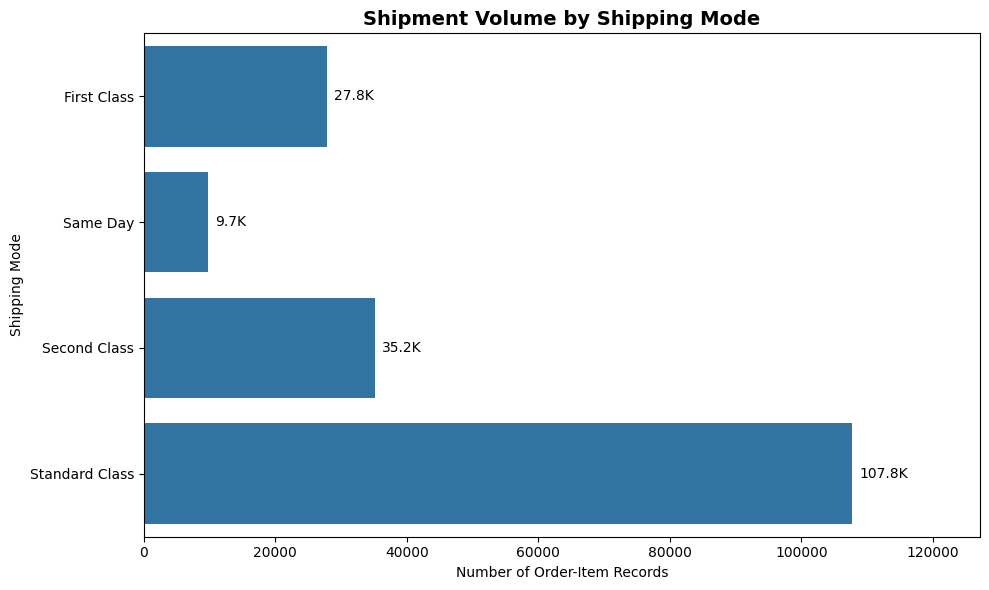

In [21]:
# Step 11B — Visualize shipment volume by shipping mode

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=shipping_analysis,
    x="Total_Records",
    y="Shipping Mode"
)

labels = [
    f"{value / 1000:,.1f}K"
    for value in shipping_analysis["Total_Records"]
]

ax.bar_label(
    ax.containers[0],
    labels=labels,
    padding=5,
    fontsize=10
)

plt.title(
    "Shipment Volume by Shipping Mode",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Number of Order-Item Records")
plt.ylabel("Shipping Mode")
plt.xlim(0, shipping_analysis["Total_Records"].max() * 1.18)

plt.tight_layout()
plt.show()


In [22]:
# Step 12A: Calculate delivery delay
# Calculate operational delay against the scheduled shipping duration
df_clean["Operational Delay Days"] = (
    df_clean["Calculated Shipping Days"]
    - df_clean["Days for shipment (scheduled)"]
)

# Classify shipping performance
df_clean["Shipping Performance Calculated"] = np.select(
    [
        df_clean["Operational Delay Days"] < 0,
        df_clean["Operational Delay Days"] == 0,
        df_clean["Operational Delay Days"] > 0
    ],
    [
        "Early",
        "On Time",
        "Delayed"
    ],
    default="Unknown"
)

# Summarize shipping performance
shipping_performance = (
    df_clean.groupby("Shipping Performance Calculated", dropna=False)
    .agg(
        Total_Records=("Shipping Performance Calculated", "size"),
        Average_Delay_Days=("Operational Delay Days", "mean")
    )
    .reset_index()
    .round(2)
)

display(shipping_performance)

,Shipping Performance Calculated,Total_Records,Average_Delay_Days
0,Delayed,62640,1.62
1,Early,25906,-1.50
2,On Time,20870,0.00
3,Unknown,71103,NaN


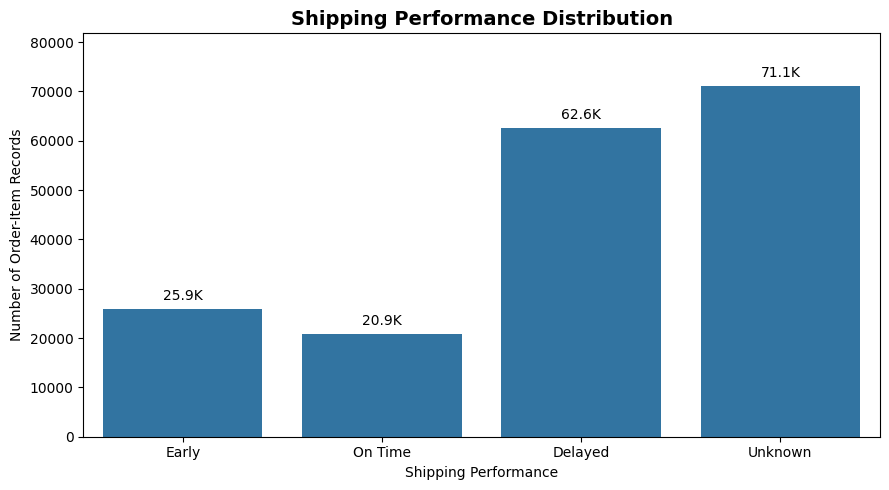

In [23]:
# Step 12B: Visualize shipping performance
performance_counts = (
    df_clean["Shipping Performance Calculated"]
    .value_counts()
    .reindex(["Early", "On Time", "Delayed", "Unknown"], fill_value=0)
    .reset_index()
)

performance_counts.columns = ["Shipping Performance", "Total Records"]

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=performance_counts,
    x="Shipping Performance",
    y="Total Records"
)

labels = [
    f"{value / 1000:,.1f}K"
    for value in performance_counts["Total Records"]
]

ax.bar_label(ax.containers[0], labels=labels, padding=4)

plt.title("Shipping Performance Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Shipping Performance")
plt.ylabel("Number of Order-Item Records")
plt.ylim(0, performance_counts["Total Records"].max() * 1.15)
plt.tight_layout()
plt.show()

In [24]:
# Step 13 — Analyze shipping performance by market
market_shipping_analysis = (
    df_clean.groupby("Market", dropna=False)
    .agg(
        Total_Records=("Market", "size"),
        Early_Shipments=(
            "Shipping Performance Calculated",
            lambda x: (x == "Early").sum()
        ),
        On_Time_Shipments=(
            "Shipping Performance Calculated",
            lambda x: (x == "On Time").sum()
        ),
        Delayed_Shipments=(
            "Shipping Performance Calculated",
            lambda x: (x == "Delayed").sum()
        ),
        Average_Operational_Delay=(
            "Operational Delay Days", "mean"
        )
    )
    .reset_index()
    .round(2)
)

market_shipping_analysis["Delayed_Percentage"] = (
    market_shipping_analysis["Delayed_Shipments"]
    / market_shipping_analysis["Total_Records"] * 100
).round(2)

market_shipping_analysis = market_shipping_analysis.sort_values(
    "Delayed_Percentage", ascending=False
)

display(market_shipping_analysis)

,Market,Total_Records,Early_Shipments,On_Time_Shipments,Delayed_Shipments,Average_Operational_Delay,Delayed_Percentage
3,Pacific Asia,41260,6207,5005,14735,0.57,35.71
0,Africa,11614,1577,1371,4082,0.59,35.15
1,Europe,50252,7081,5625,17489,0.58,34.80
2,LATAM,51594,7448,5881,17618,0.55,34.15
4,USCA,25799,3593,2988,8716,0.58,33.78


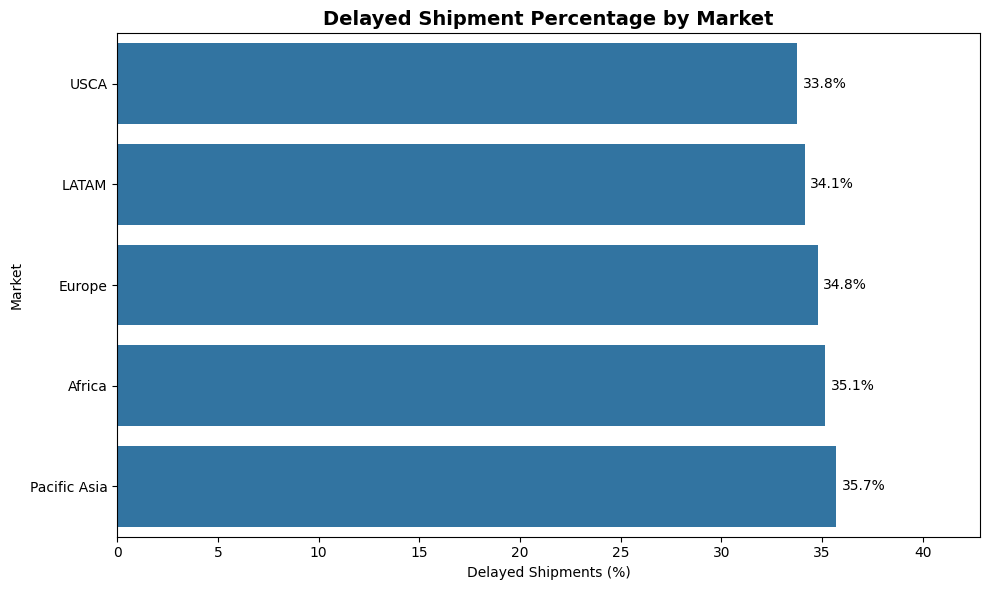

In [25]:
# Step 13B — Visualize delayed shipments by market
plt.figure(figsize=(10, 6))

plot_data = market_shipping_analysis.sort_values(
    "Delayed_Percentage", ascending=True
)

ax = sns.barplot(
    data=plot_data,
    x="Delayed_Percentage",
    y="Market"
)

labels = [
    f"{value:.1f}%"
    for value in plot_data["Delayed_Percentage"]
]

ax.bar_label(ax.containers[0], labels=labels, padding=4)

plt.title("Delayed Shipment Percentage by Market",
          fontsize=14, fontweight="bold")
plt.xlabel("Delayed Shipments (%)")
plt.ylabel("Market")
plt.xlim(0, max(plot_data["Delayed_Percentage"].max() * 1.2, 1))
plt.tight_layout()
plt.show()

Step 14 — Monthly Sales and Profit Trends to understand how supply-chain performance changes over time.

Step 14A — Prepare monthly analysis

In [26]:
# Extract year and month from the order date
df_clean["Order Month"] = (
    df_clean["order date (DateOrders)"].dt.to_period("M").astype(str)
)

monthly_analysis = (
    df_clean.groupby("Order Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Total_Records=("Order Month", "size")
    )
    .reset_index()
)

monthly_analysis["Profit_Margin_Percent"] = (
    monthly_analysis["Total_Profit"]
    / monthly_analysis["Total_Sales"].replace(0, np.nan)
    * 100
).round(2)

display(monthly_analysis.head())
print("Number of months:", len(monthly_analysis))

,Order Month,Total_Sales,Total_Profit,Total_Records,Profit_Margin_Percent
0,2015-01,"643,582.21","66,637.49",3269,10.35
1,2015-02,"541,741.24","55,944.76",2704,10.33
2,2015-03,"637,462.04","75,522.86",3239,11.85
3,2015-04,"601,342.84","67,138.15",3036,11.16
4,2015-05,"656,273.46","71,363.84",3349,10.87


Number of months: 37


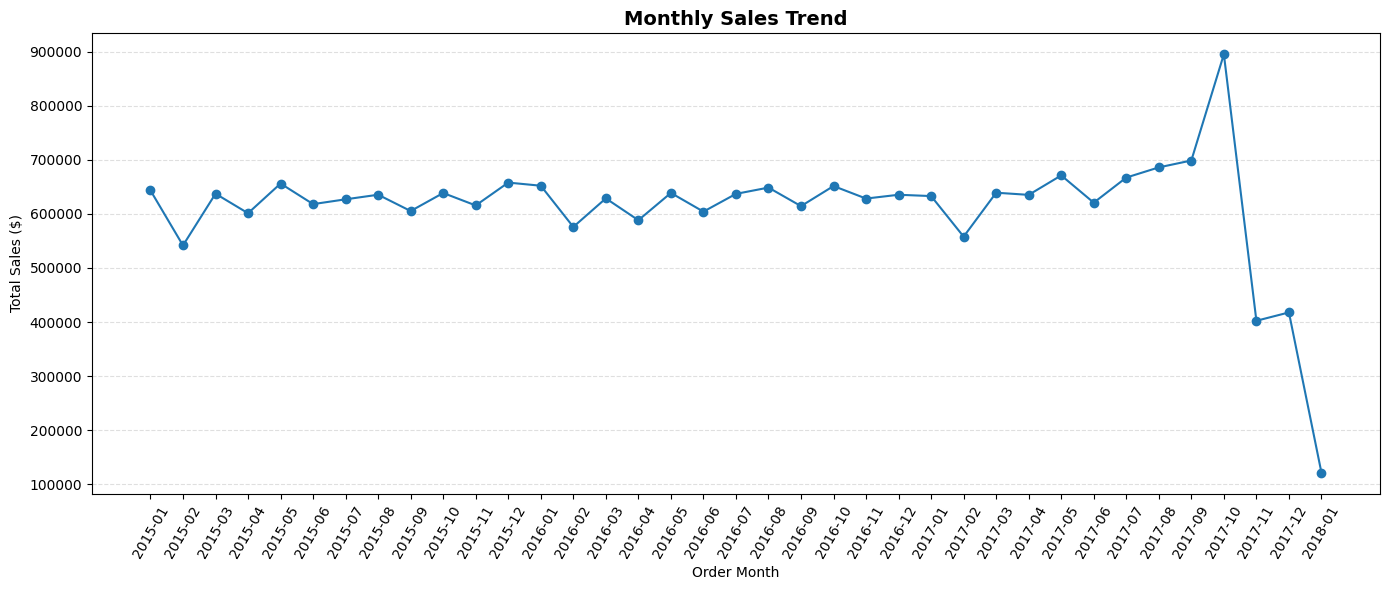

In [27]:
# Step 14B — Visualize monthly sales
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Order Month"],
    monthly_analysis["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend", fontsize=14, fontweight="bold")
plt.xlabel("Order Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=60)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

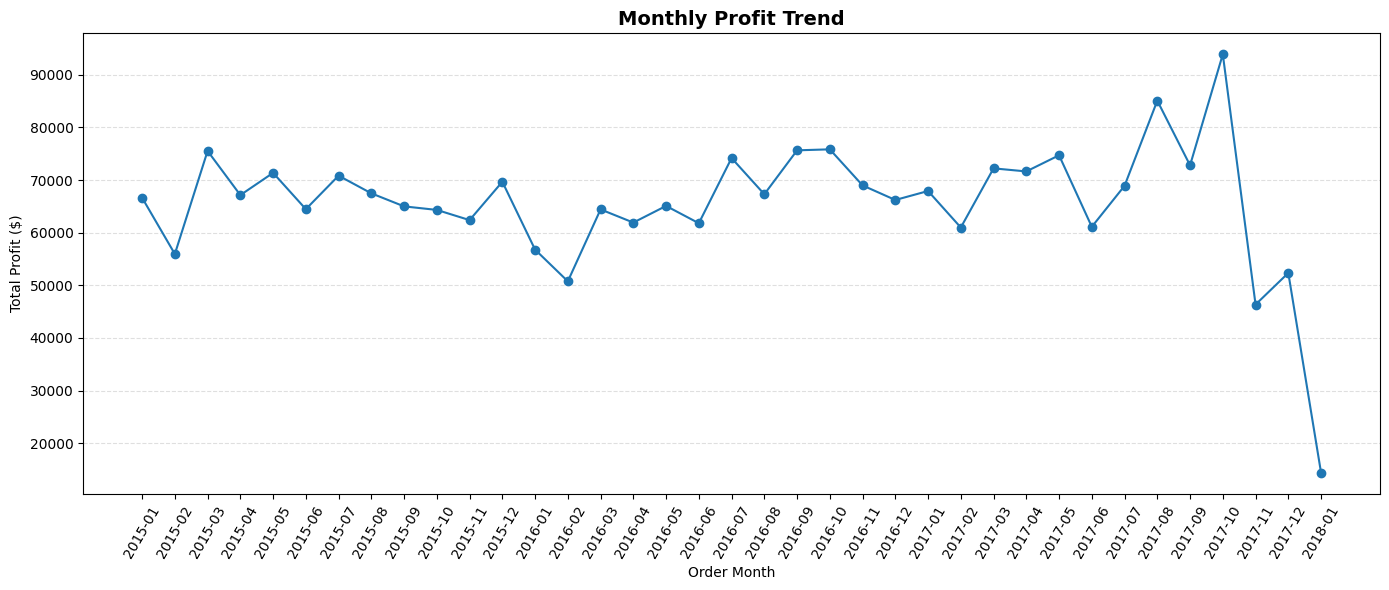

In [28]:
# Step 14C — Visualize monthly profit
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_analysis["Order Month"],
    monthly_analysis["Total_Profit"],
    marker="o"
)

plt.title("Monthly Profit Trend", fontsize=14, fontweight="bold")
plt.xlabel("Order Month")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=60)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Step 15 — Late Delivery Risk Analysis to identify which factors are associated with delivery risk.

Step 15A — Analyze late delivery risk

In [29]:
late_risk_analysis = (
    df_clean.groupby("Late_delivery_risk", dropna=False)
    .agg(
        Total_Records=("Late_delivery_risk", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Average_Shipping_Days=("Calculated Shipping Days", "mean"),
        Average_Scheduled_Days=("Days for shipment (scheduled)", "mean")
    )
    .reset_index()
    .round(2)
)

display(late_risk_analysis)

,Late_delivery_risk,Total_Records,Total_Sales,Total_Profit,Average_Shipping_Days,Average_Scheduled_Days
0,0,81542,"16,658,339.43","1,826,851.29",2.78,3.49
1,1,98977,"20,126,394.88","2,140,051.68",4.09,2.47


In [30]:
# Step 15B — Compare risk by shipping mode
risk_by_shipping_mode = (
    df_clean.groupby("Shipping Mode", dropna=False)
    .agg(
        Total_Records=("Shipping Mode", "size"),
        Late_Risk_Records=("Late_delivery_risk", "sum")
    )
    .reset_index()
)

risk_by_shipping_mode["Late_Risk_Percentage"] = (
    risk_by_shipping_mode["Late_Risk_Records"]
    / risk_by_shipping_mode["Total_Records"] * 100
).round(2)

risk_by_shipping_mode = risk_by_shipping_mode.sort_values(
    "Late_Risk_Percentage", ascending=False
)

display(risk_by_shipping_mode)

,Shipping Mode,Total_Records,Late_Risk_Records,Late_Risk_Percentage
0,First Class,27814,26513,95.32
2,Second Class,35216,26987,76.63
1,Same Day,9737,4454,45.74
3,Standard Class,107752,41023,38.07


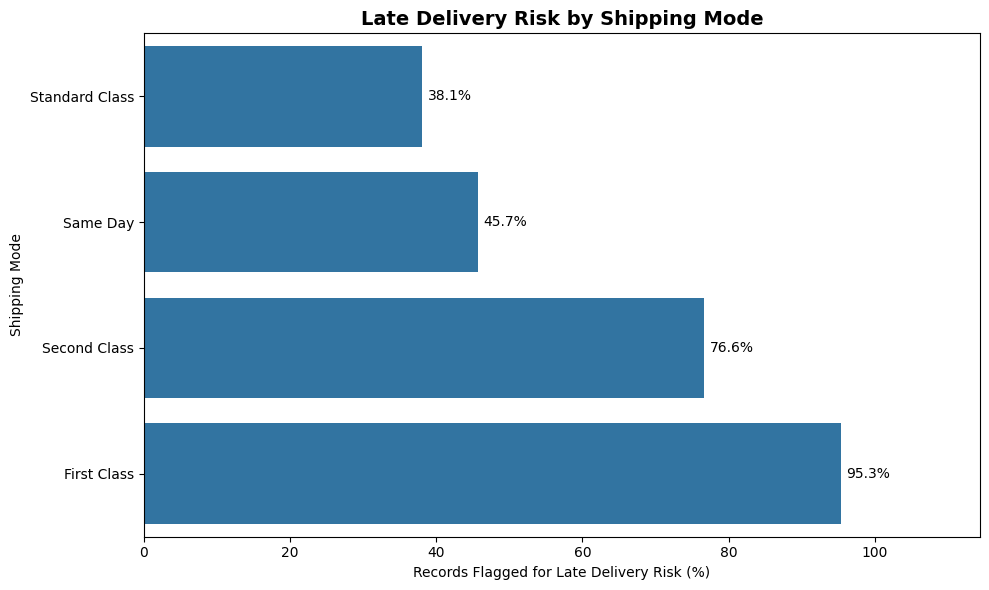

In [31]:
# Step 15C — Visualize risk by shipping mode
plt.figure(figsize=(10, 6))

plot_data = risk_by_shipping_mode.sort_values(
    "Late_Risk_Percentage", ascending=True
)

ax = sns.barplot(
    data=plot_data,
    x="Late_Risk_Percentage",
    y="Shipping Mode"
)

labels = [
    f"{value:.1f}%"
    for value in plot_data["Late_Risk_Percentage"]
]

ax.bar_label(ax.containers[0], labels=labels, padding=4)

plt.title("Late Delivery Risk by Shipping Mode",
          fontsize=14, fontweight="bold")
plt.xlabel("Records Flagged for Late Delivery Risk (%)")
plt.ylabel("Shipping Mode")
plt.xlim(0, max(plot_data["Late_Risk_Percentage"].max() * 1.2, 1))
plt.tight_layout()
plt.show()

Step 16 — Correlation Analysis to explore relationships between sales, profit, shipping duration, and late-delivery risk.

Step 16A — Create the correlation matrix

In [32]:
correlation_columns = [
    "Sales",
    "Order Profit Per Order",
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Late_delivery_risk",
    "Operational Delay Days"
]

correlation_data = df_clean[correlation_columns].apply(
    pd.to_numeric, errors="coerce"
)

correlation_matrix = correlation_data.corr()

display(correlation_matrix.round(2))

,Sales,Order Profit Per Order,Days for shipping (real),Days for shipment (scheduled),Late_delivery_risk,Operational Delay Days
Sales,1.00,0.13,0.00,0.01,-0.00,-0.01
Order Profit Per Order,0.13,1.00,-0.01,-0.00,-0.00,-0.01
Days for shipping (real),0.00,-0.01,1.00,0.52,0.40,0.61
Days for shipment (scheduled),0.01,-0.00,0.52,1.00,-0.37,-0.35
Late_delivery_risk,-0.00,-0.00,0.40,-0.37,1.00,0.77
Operational Delay Days,-0.01,-0.01,0.61,-0.35,0.77,1.00


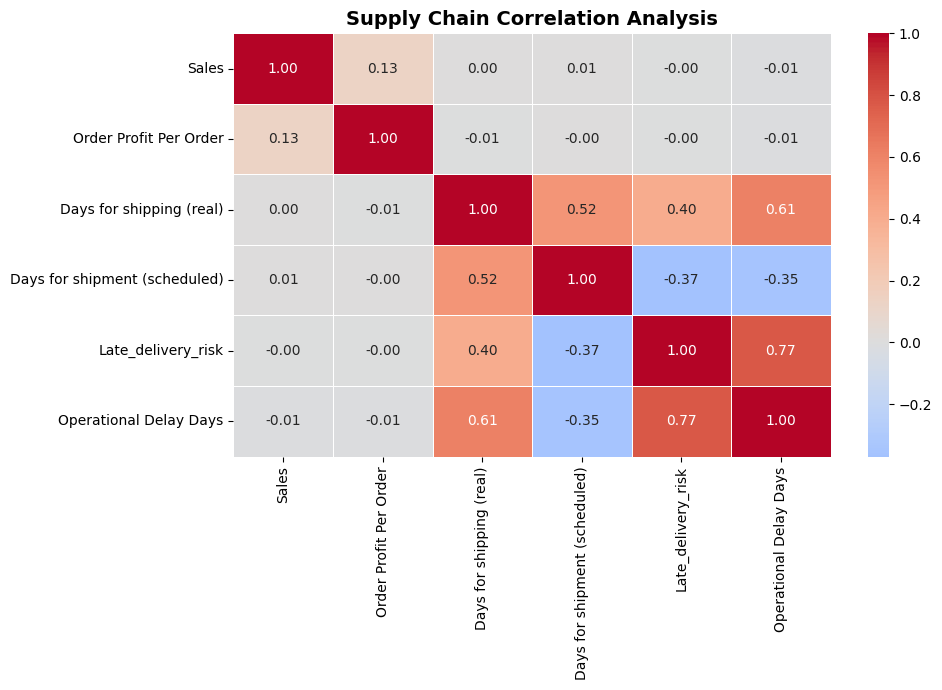

In [33]:
# Step 16B — Visualize the correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Supply Chain Correlation Analysis",
          fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [34]:
# Step 16C — Identify the strongest relationships with late-delivery risk
risk_correlations = (
    correlation_matrix["Late_delivery_risk"]
    .drop("Late_delivery_risk")
    .sort_values(key=lambda x: x.abs(), ascending=False)
    .reset_index()
)

risk_correlations.columns = [
    "Variable",
    "Correlation with Late Delivery Risk"
]

display(risk_correlations.round(3))

,Variable,Correlation with Late Delivery Risk
0,Operational Delay Days,0.78
1,Days for shipping (real),0.40
2,Days for shipment (scheduled),-0.37
3,Order Profit Per Order,-0.00
4,Sales,-0.00


Step 17 — Identify the Top and Bottom Performing Categories.

In [35]:
# Step 17A — Rank categories by sales and profit
category_ranking = (
    df_clean.groupby("Category Name", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Total_Records=("Category Name", "size")
    )
    .reset_index()
)

category_ranking["Profit_Margin_Percent"] = (
    category_ranking["Total_Profit"]
    / category_ranking["Total_Sales"].replace(0, np.nan)
    * 100
).round(2)

category_ranking = category_ranking.sort_values(
    "Total_Profit", ascending=False
)

print("TOP 10 CATEGORIES BY PROFIT")
display(category_ranking.head(10))

print("BOTTOM 10 CATEGORIES BY PROFIT")
display(category_ranking.tail(10))

TOP 10 CATEGORIES BY PROFIT


,Category Name,Total_Sales,Total_Profit,Total_Records,Profit_Margin_Percent
18,Fishing,"6,929,653.50","756,220.76",17325,10.91
12,Cleats,"4,431,942.66","494,636.92",24551,11.16
9,Camping & Hiking,"4,118,425.42","427,455.57",13729,10.38
10,Cardio Equipment,"3,694,843.20","383,011.10",12487,10.37
47,Women's Apparel,"3,147,800.00","350,421.03",21035,11.13
46,Water Sports,"3,113,844.60","325,146.96",15540,10.44
30,Indoor/Outdoor Games,"2,888,993.94","318,451.43",19298,11.02
34,Men's Footwear,"2,891,757.54","311,902.82",22246,10.79
38,Shop By Sport,"1,309,522.02","129,813.96",10984,9.91
13,Computers,"663,000.00","69,656.81",442,10.51


BOTTOM 10 CATEGORIES BY PROFIT


,Category Name,Total_Sales,Total_Profit,Total_Records,Profit_Margin_Percent
45,Video Games,"33,310.50","2,717.52",838,8.16
33,Men's Clothing,"43,856.80","2,006.04",208,4.57
4,Basketball,"27,099.33","1,845.67",67,6.81
23,Golf Bags & Carts,"10,369.39","1,810.07",61,17.46
2,Baby,"12,229.56","1,525.03",207,12.47
43,Toys,"6,104.66",900.71,529,14.75
5,Books,"12,587.40",883.01,405,7.02
1,As Seen on TV!,"20,597.94",714.43,68,3.47
7,CDs,"3,059.59",383.85,271,12.55
41,Strength Training,"54,895.53",332.31,111,0.61


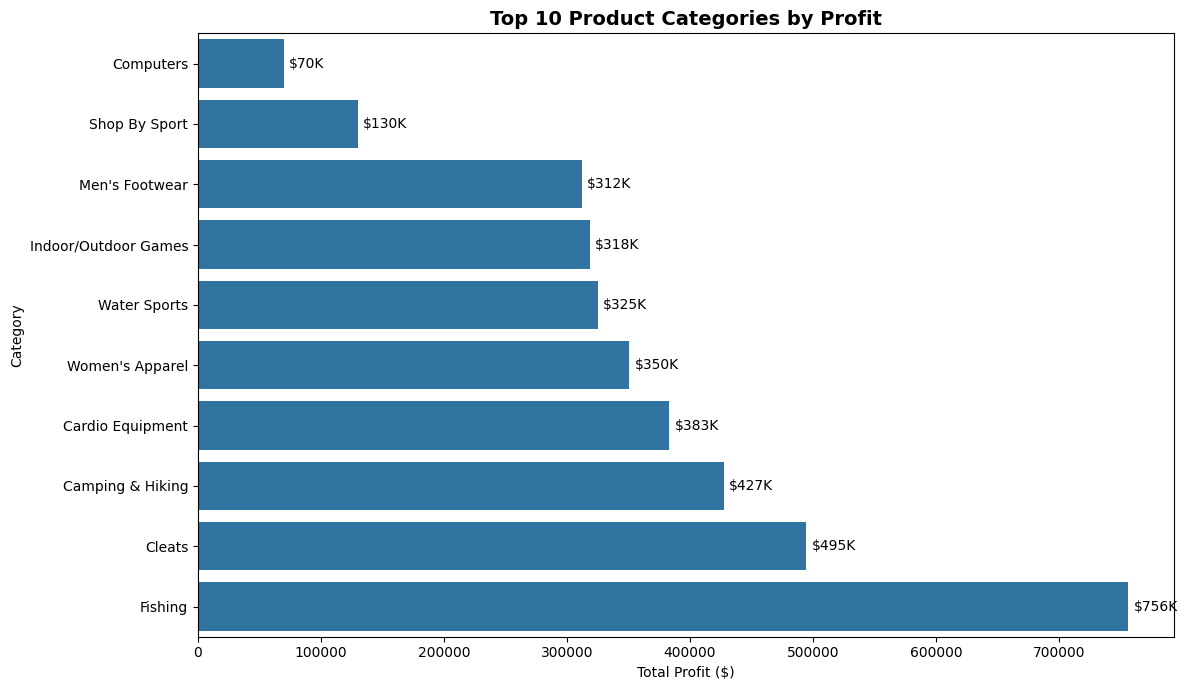

In [36]:
# Step 17B — Visualize the top 10 categories by profit
top_categories = (
    category_ranking.nlargest(10, "Total_Profit")
    .sort_values("Total_Profit", ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top_categories,
    x="Total_Profit",
    y="Category Name"
)

labels = [
    f"${value / 1000:,.0f}K"
    for value in top_categories["Total_Profit"]
]

ax.bar_label(ax.containers[0], labels=labels, padding=4)

plt.title("Top 10 Product Categories by Profit",
          fontsize=14, fontweight="bold")
plt.xlabel("Total Profit ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Step 18 — Validate Python Results Against SQL Server.

In [37]:
# Step 18A — Compare the main KPIs
python_kpis = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Total Sales",
        "Total Profit",
        "Average Sales per Record",
        "Overall Profit Margin (%)"
    ],
    "Python Value": [
        len(df_clean),
        df_clean["Sales"].sum(),
        df_clean["Order Profit Per Order"].sum(),
        df_clean["Sales"].mean(),
        (
            df_clean["Order Profit Per Order"].sum()
            / df_clean["Sales"].sum() * 100
            if df_clean["Sales"].sum() != 0 else np.nan
        )
    ]
})

display(python_kpis.round(2))

,Metric,Python Value
0,Total Records,"180,519.00"
1,Total Sales,"36,784,734.31"
2,Total Profit,"3,966,902.97"
3,Average Sales per Record,203.77
4,Overall Profit Margin (%),10.78


In [38]:
print("Total rows:", f"{len(df_clean):,}")
print("Unique Order Id:", f"{df_clean['Order Id'].nunique():,}")
print("Missing Order Id:", f"{df_clean['Order Id'].isna().sum():,}")

Total rows: 180,519
Unique Order Id: 65,752
Missing Order Id: 0


In [40]:
total_orders = df_clean["Order Id"].nunique()
print(f"Total Orders: {total_orders:,}")

Total Orders: 65,752


In [42]:
total_records = len(df_clean)

late_records = (
    df_clean["Delivery Status"].eq("Late delivery").sum()
)

non_cancelled_records = (
    df_clean["Delivery Status"].ne("Shipping canceled").sum()
)

print(f"All records: {total_records:,}")
print(f"Late-delivery records: {late_records:,}")
print(f"Late % of all records: {late_records / total_records * 100:.2f}%")
print(
    f"Late % excluding cancelled: "
    f"{late_records / non_cancelled_records * 100:.2f}%"
)

All records: 180,519
Late-delivery records: 98,977
Late % of all records: 54.83%
Late % excluding cancelled: 57.29%


In [43]:
# Step 19 — Final Python Business Insights

# 1. Overall KPIs
total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Order Profit Per Order"].sum()

print("=== SUPPLY CHAIN BUSINESS SUMMARY ===")
print(f"Total records: {len(df_clean):,}")
print(f"Total sales: ${total_sales:,.2f}")
print(f"Total profit: ${total_profit:,.2f}")
print(f"Profit margin: {(total_profit / total_sales * 100):.2f}%")

# 2. Highest-sales market
best_sales_market = market_analysis.loc[
    market_analysis["Total_Sales"].idxmax()
]
print("\n=== MARKET PERFORMANCE ===")
print(f"Highest-sales market: {best_sales_market['Market']}")
print(f"Market sales: ${best_sales_market['Total_Sales']:,.2f}")

# 3. Most profitable category
best_category = category_ranking.loc[
    category_ranking["Total_Profit"].idxmax()
]
print("\n=== CATEGORY PROFITABILITY ===")
print(f"Most profitable category: {best_category['Category Name']}")
print(f"Category profit: ${best_category['Total_Profit']:,.2f}")

# 4. Market with the highest date-calculated delay percentage
worst_delay_market = market_shipping_analysis.loc[
    market_shipping_analysis["Delayed_Percentage"].idxmax()
]
print("\n=== SHIPPING PERFORMANCE ===")
print(f"Highest delayed-shipment market: {worst_delay_market['Market']}")
print(
    f"Delayed records: {worst_delay_market['Delayed_Percentage']:.2f}%"
)

# 5. Monthly trend extremes
best_sales_month = monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmax()
]
worst_sales_month = monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmin()
]

print("\n=== MONTHLY SALES ===")
print(
    f"Highest-sales month: {best_sales_month['Order Month']} "
    f"(${best_sales_month['Total_Sales']:,.2f})"
)
print(
    f"Lowest-sales month: {worst_sales_month['Order Month']} "
    f"(${worst_sales_month['Total_Sales']:,.2f})"
)


=== SUPPLY CHAIN BUSINESS SUMMARY ===
Total records: 180,519
Total sales: $36,784,734.31
Total profit: $3,966,902.97
Profit margin: 10.78%

=== MARKET PERFORMANCE ===
Highest-sales market: Europe
Market sales: $10,872,396.60

=== CATEGORY PROFITABILITY ===
Most profitable category: Fishing
Category profit: $756,220.76

=== SHIPPING PERFORMANCE ===
Highest delayed-shipment market: Pacific Asia
Delayed records: 35.71%

=== MONTHLY SALES ===
Highest-sales month: 2017-10 ($895,572.52)
Lowest-sales month: 2018-01 ($121,139.25)


In [44]:
total_orders = df_clean["Order Id"].nunique()

total_records = len(df_clean)

late_records = df_clean["Delivery Status"].eq("Late delivery").sum()

cancelled_records = df_clean["Delivery Status"].eq("Shipping canceled").sum()

eligible_records = total_records - cancelled_records

late_delivery_pct = late_records / eligible_records * 100

print(f"Total Orders: {total_orders:,}")
print(f"Total Records: {total_records:,}")
print(f"Late Delivery Records: {late_records:,}")
print(f"Cancelled Records: {cancelled_records:,}")
print(f"Eligible Records: {eligible_records:,}")
print(f"Late Delivery %: {late_delivery_pct:.2f}%")

Total Orders: 65,752
Total Records: 180,519
Late Delivery Records: 98,977
Cancelled Records: 7,754
Eligible Records: 172,765
Late Delivery %: 57.29%
